# Task 4: Unveiling the Android App Market
## Google Play Store Data Analysis and Sentiment Analysis

### Objective
Analyze Google Play Store applications to understand category distribution, ratings, installs, app sizes, pricing, and user sentiment.

### Tools Used
- Python
- pandas and NumPy
- Matplotlib and Seaborn
- TextBlob
- Plotly
- Jupyter Notebook

### Project Workflow
1. Load and inspect both datasets.
2. Clean missing values, duplicates, and incorrect data types.
3. Analyze app categories, ratings, size, installs, and pricing.
4. Perform sentiment analysis on user reviews.
5. Compare sentiment across app categories.
6. Create an interactive visualization.
7. Summarize three insights for app developers.

In [1]:
%pip install pandas numpy matplotlib seaborn textblob plotly

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 4.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from textblob import TextBlob
from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Loading the Datasets

Load the Google Play Store apps dataset and user reviews dataset separately. These datasets will be used for app-level analysis and review sentiment analysis.

In [3]:
apps_path = "data/googleplaystore.csv"
reviews_path = "data/googleplaystore_user_reviews.csv"

if not os.path.exists(apps_path):
    raise FileNotFoundError(
        f"Apps dataset not found: {apps_path}. "
        "Check that the CSV file is inside the data folder."
    )

if not os.path.exists(reviews_path):
    raise FileNotFoundError(
        f"Reviews dataset not found: {reviews_path}. "
        "Check that the CSV file is inside the data folder."
    )

apps = pd.read_csv(apps_path)
reviews = pd.read_csv(reviews_path)

print("Apps dataset shape:", apps.shape)
print("Reviews dataset shape:", reviews.shape)

print("\nApps dataset columns:")
print(apps.columns.tolist())

print("\nReviews dataset columns:")
print(reviews.columns.tolist())

Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)

Apps dataset columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Reviews dataset columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


## 2. Initial Data Inspection

Inspect the first few records, column data types, and dataset structure to understand the available information and identify potential data-quality issues.

In [4]:
print("First five app records:")
display(apps.head())

print("\nApps dataset information:")
apps.info()

print("\nFirst five review records:")
display(reviews.head())

print("\nReviews dataset information:")
reviews.info()

First five app records:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



Apps dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB

First five review records:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000



Reviews dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 8.3 MB


In [5]:
print("Missing values in apps dataset:")
display(apps.isnull().sum().sort_values(ascending=False))

print("\nMissing values in reviews dataset:")
display(reviews.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows in apps dataset:", apps.duplicated().sum())
print("Duplicate rows in reviews dataset:", reviews.duplicated().sum())

Missing values in apps dataset:


Rating            1474
Current Ver          8
Android Ver          3
Content Rating       1
Type                 1
Size                 0
Reviews              0
Category             0
App                  0
Price                0
Installs             0
Last Updated         0
Genres               0
dtype: int64


Missing values in reviews dataset:


Translated_Review         26868
Sentiment_Polarity        26863
Sentiment                 26863
Sentiment_Subjectivity    26863
App                           0
dtype: int64


Duplicate rows in apps dataset: 483
Duplicate rows in reviews dataset: 33616


## 3. Data Cleaning — Google Play Store Apps

The apps dataset contains missing values, duplicate records, and inconsistent data types. The cleaning process removes duplicate applications, converts numeric columns into usable formats, and handles invalid values.

In [6]:
# Create working copies so the original data remains unchanged
apps_clean = apps.copy()
reviews_clean = reviews.copy()

# Remove duplicate app records
apps_clean = apps_clean.drop_duplicates()

# Remove leading and trailing spaces from text columns
for col in apps_clean.select_dtypes(include="object").columns:
    apps_clean[col] = apps_clean[col].str.strip()

print("Original apps rows:", len(apps))
print("Rows after removing exact duplicates:", len(apps_clean))
print("Duplicate rows remaining:", apps_clean.duplicated().sum())

Original apps rows: 10841
Rows after removing exact duplicates: 10358
Duplicate rows remaining: 0


In [7]:
# Clean Rating
apps_clean["Rating"] = pd.to_numeric(
    apps_clean["Rating"], errors="coerce"
)

# Clean Installs: remove commas and plus signs
apps_clean["Installs"] = pd.to_numeric(
    apps_clean["Installs"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

# Clean Price: remove currency symbols
apps_clean["Price"] = pd.to_numeric(
    apps_clean["Price"]
    .astype("string")
    .str.replace("$", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Clean Size: convert K and M to megabytes
def convert_size(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    if value == "Varies with device":
        return np.nan

    try:
        if value.endswith("M"):
            return float(value[:-1])
        elif value.endswith("k"):
            return float(value[:-1]) / 1024
        else:
            return np.nan
    except ValueError:
        return np.nan

apps_clean["Size_MB"] = apps_clean["Size"].apply(convert_size)

print("Numeric columns cleaned successfully.")
display(apps_clean[["App", "Rating", "Size", "Size_MB",
                    "Installs", "Price"]].head(10))

Numeric columns cleaned successfully.


,App,Rating,Size,Size_MB,Installs,Price
0,Photo Editor & Candy Camera & Grid & ScrapBook,4.1,19M,19.0,10000,0.0
1,Coloring book moana,3.9,14M,14.0,500000,0.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.7,8.7M,8.7,5000000,0.0
3,Sketch - Draw & Paint,4.5,25M,25.0,50000000,0.0
4,Pixel Draw - Number Art Coloring Book,4.3,2.8M,2.8,100000,0.0
5,Paper flowers instructions,4.4,5.6M,5.6,50000,0.0
6,Smoke Effect Photo Maker - Smoke Editor,3.8,19M,19.0,50000,0.0
7,Infinite Painter,4.1,29M,29.0,1000000,0.0
8,Garden Coloring Book,4.4,33M,33.0,1000000,0.0
9,Kids Paint Free - Drawing Fun,4.7,3.1M,3.1,10000,0.0


In [8]:
# Remove rows with missing app names
apps_clean = apps_clean.dropna(subset=["App"])

# Keep valid rating values between 1 and 5
apps_clean.loc[
    ~apps_clean["Rating"].between(1, 5), "Rating"
] = np.nan

# Keep non-negative installs and prices
apps_clean.loc[apps_clean["Installs"] < 0, "Installs"] = np.nan
apps_clean.loc[apps_clean["Price"] < 0, "Price"] = np.nan

# Remove known invalid category entries
apps_clean = apps_clean[
    apps_clean["Category"].notna()
    & (apps_clean["Category"] != "1.9")
].copy()

# Standardize category names
apps_clean["Category"] = apps_clean["Category"].str.upper()

# Handle review data
reviews_clean = reviews_clean.drop_duplicates()

# Remove rows without actual review text
reviews_clean = reviews_clean.dropna(
    subset=["Translated_Review"]
).copy()

# Remove empty review text
reviews_clean["Translated_Review"] = (
    reviews_clean["Translated_Review"].astype(str).str.strip()
)

reviews_clean = reviews_clean[
    reviews_clean["Translated_Review"] != ""
].copy()

print("Clean apps shape:", apps_clean.shape)
print("Clean reviews shape:", reviews_clean.shape)

print("\nRemaining missing values in apps:")
display(apps_clean.isnull().sum().sort_values(ascending=False))

print("\nRemaining missing values in reviews:")
display(reviews_clean.isnull().sum().sort_values(ascending=False))

Clean apps shape: (10357, 14)
Clean reviews shape: (29692, 5)

Remaining missing values in apps:


Size_MB           1526
Rating            1465
Current Ver          8
Android Ver          2
Type                 1
App                  0
Installs             0
Size                 0
Reviews              0
Category             0
Genres               0
Content Rating       0
Price                0
Last Updated         0
dtype: int64


Remaining missing values in reviews:


App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64

### Data Cleaning Results

The cleaned datasets are checked for remaining duplicates, invalid ratings, and inconsistent numeric values. Missing values are retained where appropriate for later analysis or excluded from the relevant calculations.

In [9]:
print("Final data quality checks")

print("\nApps dataset:")
print("Rows:", len(apps_clean))
print("Duplicate rows:", apps_clean.duplicated().sum())
print("Invalid ratings:",
      ((apps_clean["Rating"] < 1) |
       (apps_clean["Rating"] > 5)).sum())
print("Missing ratings:", apps_clean["Rating"].isna().sum())

print("\nReviews dataset:")
print("Rows:", len(reviews_clean))
print("Duplicate rows:", reviews_clean.duplicated().sum())
print("Missing review text:",
      reviews_clean["Translated_Review"].isna().sum())

Final data quality checks

Apps dataset:
Rows: 10357
Duplicate rows: 0
Invalid ratings: 0
Missing ratings: 1465

Reviews dataset:
Rows: 29692
Duplicate rows: 0
Missing review text: 0


## 4. Category Analysis

Analyze the number of applications in each category to understand how apps are distributed across the Google Play Store. Categories with more apps may have greater competition and market saturation.

,Number_of_Apps
Category,
FAMILY,1943
GAME,1121
TOOLS,843
BUSINESS,427
MEDICAL,408
PRODUCTIVITY,407
PERSONALIZATION,388
LIFESTYLE,373
COMMUNICATION,366


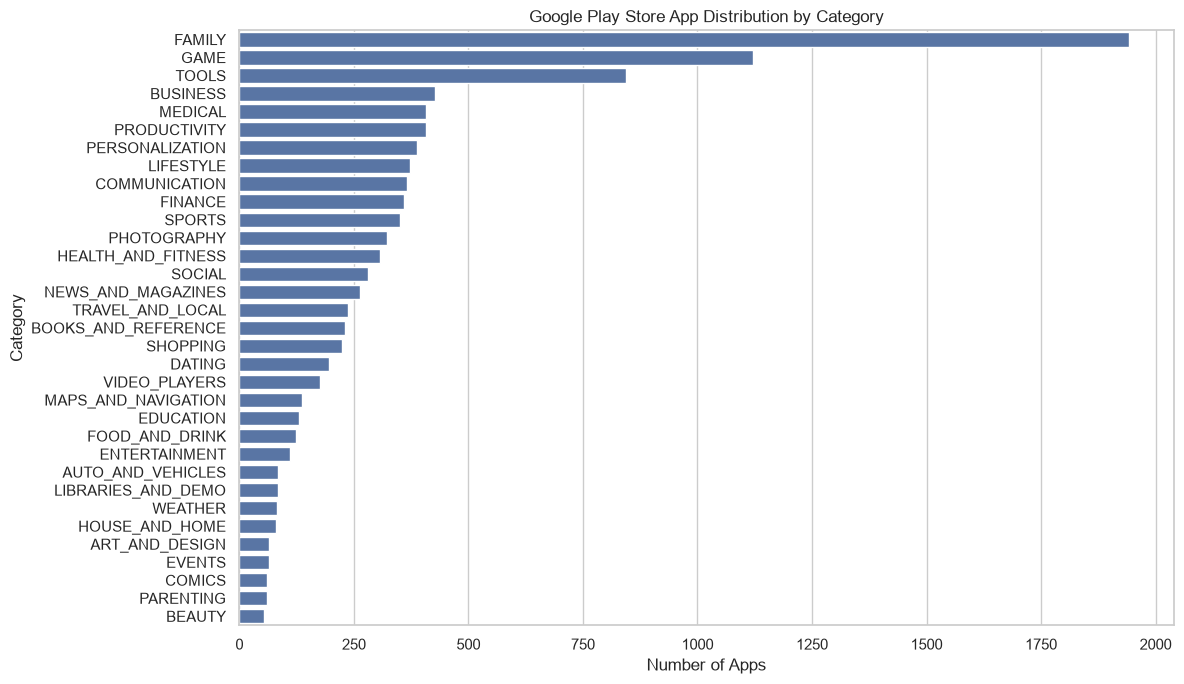

In [10]:
# Count apps in each category
category_counts = (
    apps_clean["Category"]
    .value_counts()
    .sort_values(ascending=False)
)

display(category_counts.to_frame(name="Number_of_Apps"))

# Plot category distribution
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Google Play Store App Distribution by Category")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Analysis

The bar chart compares the number of applications across categories. Categories with the largest bars have the highest number of listed apps and may face stronger competition. However, app count alone does not prove market saturation; downloads, user demand, and competition should also be considered.

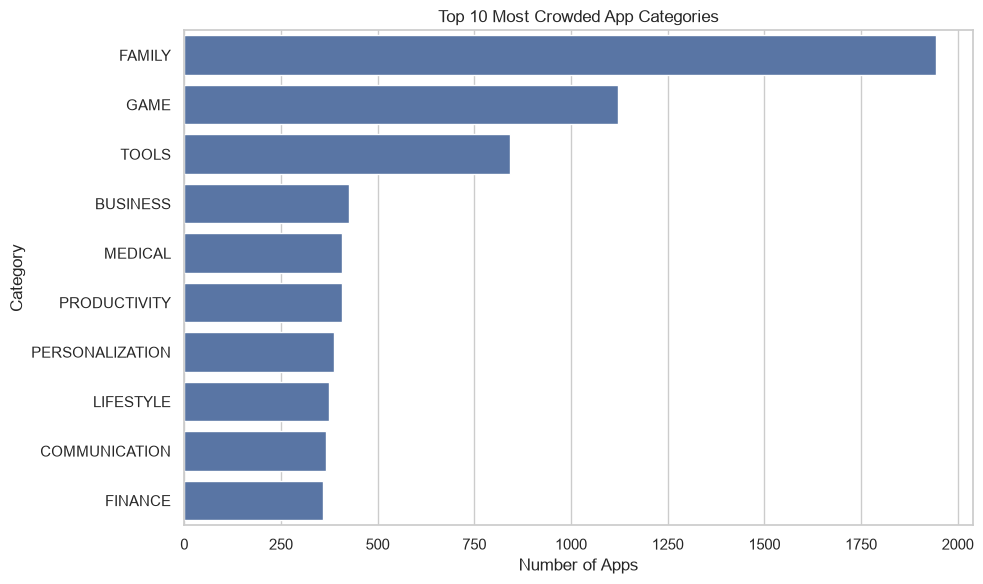

Top 5 categories by number of apps:


,Number_of_Apps
Category,
FAMILY,1943
GAME,1121
TOOLS,843
BUSINESS,427
MEDICAL,408


In [11]:
top_categories = category_counts.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 Most Crowded App Categories")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

print("Top 5 categories by number of apps:")
display(top_categories.head(5).to_frame(name="Number_of_Apps"))

### Category Saturation Analysis

The five categories with the most listed applications represent areas with a relatively large number of competing apps. A developer should compare these categories with user demand and review sentiment before deciding where to launch a new application.

## 5. Ratings Analysis

Examine the distribution of app ratings to understand how users rate applications. Ratings outside the valid range of 1 to 5 were converted to missing values during cleaning.

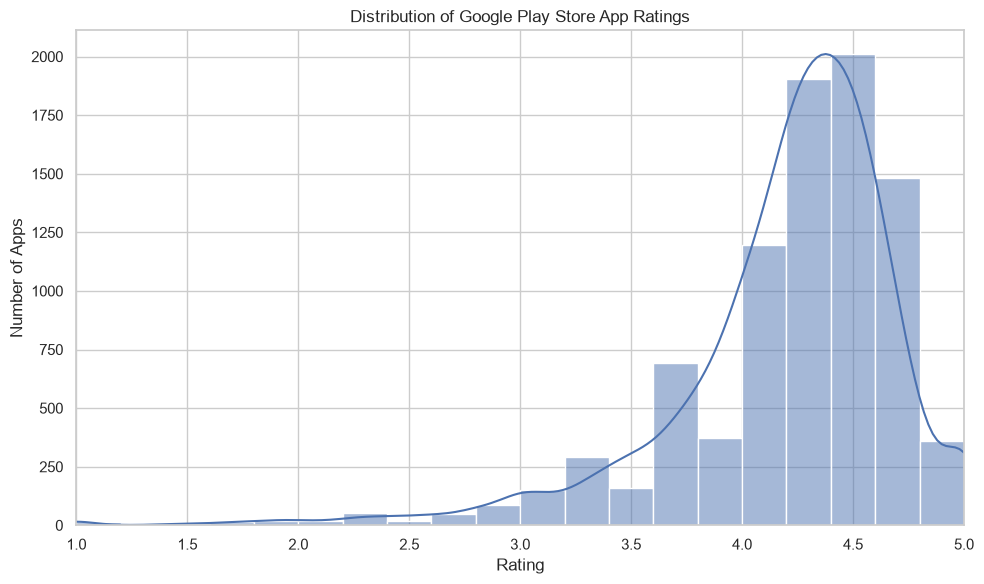

Average app rating: 4.19
Median app rating: 4.3
Number of apps with valid ratings: 8892


In [12]:
rating_data = apps_clean["Rating"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    rating_data,
    bins=20,
    kde=True
)

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.xlim(1, 5)
plt.tight_layout()
plt.show()

print("Average app rating:", round(rating_data.mean(), 2))
print("Median app rating:", round(rating_data.median(), 2))
print("Number of apps with valid ratings:", len(rating_data))

### Ratings Distribution Analysis

The histogram shows how app ratings are distributed between 1 and 5. A concentration of ratings near 4 or above suggests that many rated apps receive favorable scores. Ratings represent only users who submitted ratings and may not reflect every user's experience.

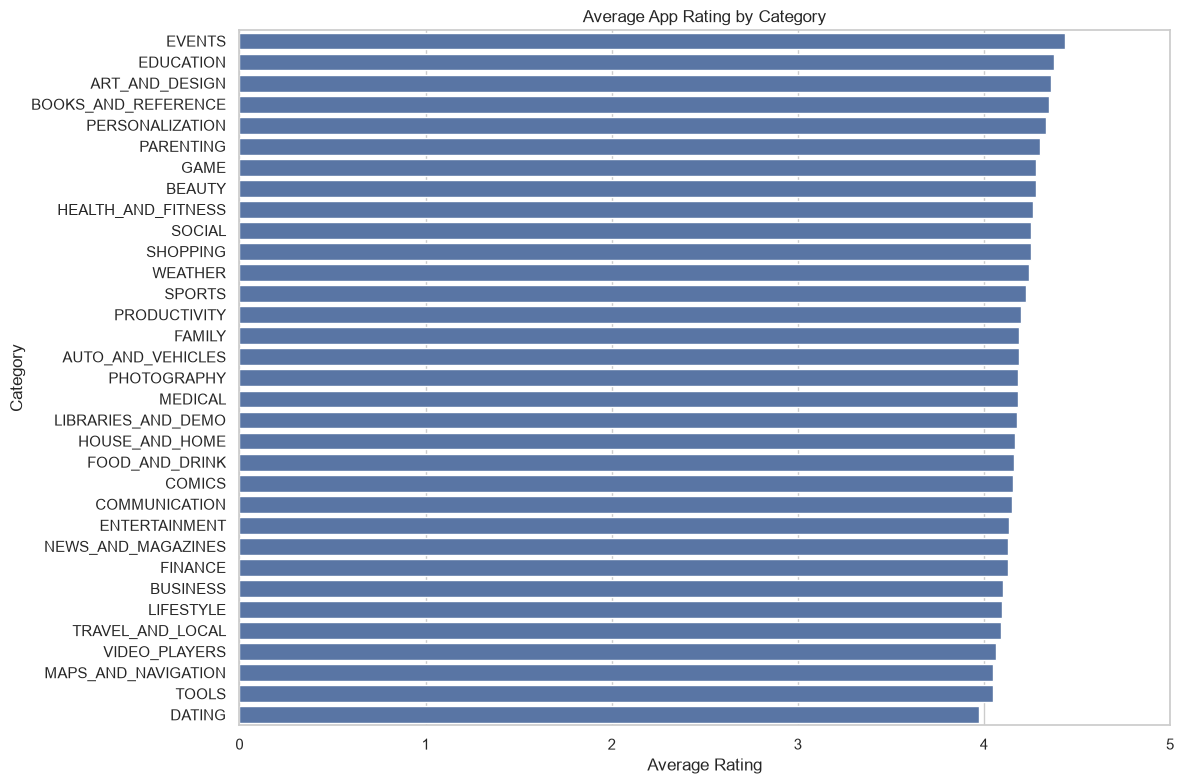

Top 10 categories by average rating:


,Average_Rating,Rated_Apps
Category,,
EVENTS,4.44,45
EDUCATION,4.38,129
ART_AND_DESIGN,4.36,62
BOOKS_AND_REFERENCE,4.35,177
PERSONALIZATION,4.33,310
PARENTING,4.30,50
GAME,4.28,1074
BEAUTY,4.28,42
HEALTH_AND_FITNESS,4.26,262



Bottom 10 categories by average rating:


,Average_Rating,Rated_Apps
Category,,
ENTERTAINMENT,4.14,111
NEWS_AND_MAGAZINES,4.13,214
FINANCE,4.13,317
BUSINESS,4.10,270
LIFESTYLE,4.10,305
TRAVEL_AND_LOCAL,4.09,205
VIDEO_PLAYERS,4.06,160
MAPS_AND_NAVIGATION,4.05,124
TOOLS,4.05,734


In [13]:
category_ratings = (
    apps_clean.groupby("Category")["Rating"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Average_Rating",
        "count": "Rated_Apps"
    })
    .dropna(subset=["Average_Rating"])
    .sort_values("Average_Rating", ascending=False)
)

# Show categories with at least 10 rated apps
category_ratings_filtered = category_ratings[
    category_ratings["Rated_Apps"] >= 10
]

plt.figure(figsize=(12, 8))

sns.barplot(
    data=category_ratings_filtered.reset_index(),
    x="Average_Rating",
    y="Category"
)

plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

print("Top 10 categories by average rating:")
display(category_ratings_filtered.head(10).round(2))

print("\nBottom 10 categories by average rating:")
display(category_ratings_filtered.tail(10).round(2))

### Average Rating by Category — Analysis

This chart compares average ratings across categories, including only categories with at least 10 rated apps to reduce the influence of very small samples. Developers can use these comparisons to identify categories where apps receive favorable ratings and categories where user experience may need improvement.

## 6. App Size and Install Analysis

Explore the relationship between application size and the number of installs. This analysis helps investigate whether larger applications tend to have more or fewer installs.

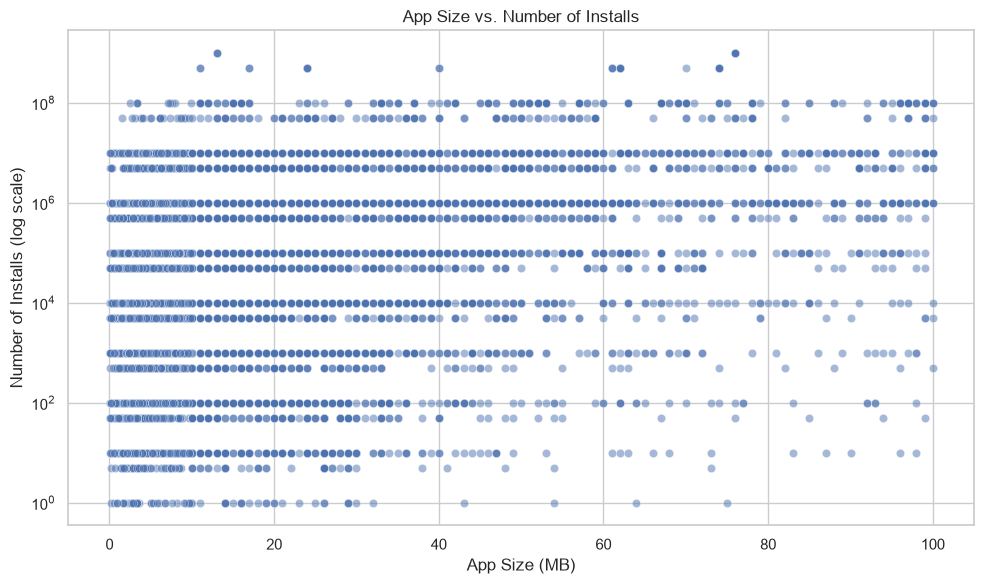

Pearson correlation: 0.169
Apps included in analysis: 8817


In [14]:
# Select valid size and install values
size_installs = apps_clean.dropna(
    subset=["Size_MB", "Installs"]
).copy()

size_installs = size_installs[
    (size_installs["Size_MB"] > 0) &
    (size_installs["Installs"] > 0)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=size_installs,
    x="Size_MB",
    y="Installs",
    alpha=0.5
)

plt.yscale("log")
plt.title("App Size vs. Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs (log scale)")
plt.tight_layout()
plt.show()

correlation = size_installs["Size_MB"].corr(
    size_installs["Installs"]
)

print("Pearson correlation:", round(correlation, 3))
print("Apps included in analysis:", len(size_installs))

In [15]:
if pd.isna(correlation):
    print("Correlation could not be calculated.")
elif correlation > 0.3:
    print("There is a positive linear relationship in this sample.")
elif correlation < -0.3:
    print("There is a negative linear relationship in this sample.")
else:
    print("The linear relationship is weak or close to zero.")

print(
    "Correlation does not prove that app size causes more or fewer installs."
)

The linear relationship is weak or close to zero.
Correlation does not prove that app size causes more or fewer installs.


### App Size and Installs — Analysis

The scatter plot compares app size with installs. The logarithmic y-axis makes it easier to view apps with widely varying install counts. Pearson correlation measures the strength of the linear relationship, but it does not establish causation. App category, popularity, and app purpose may also influence installs.

## 7. Pricing Analysis

Compare the number of free and paid applications and examine the listed prices of paid apps. This helps describe the pricing patterns of applications in the dataset.

,Number_of_Apps
App_Type,
Free,9592
Paid,765


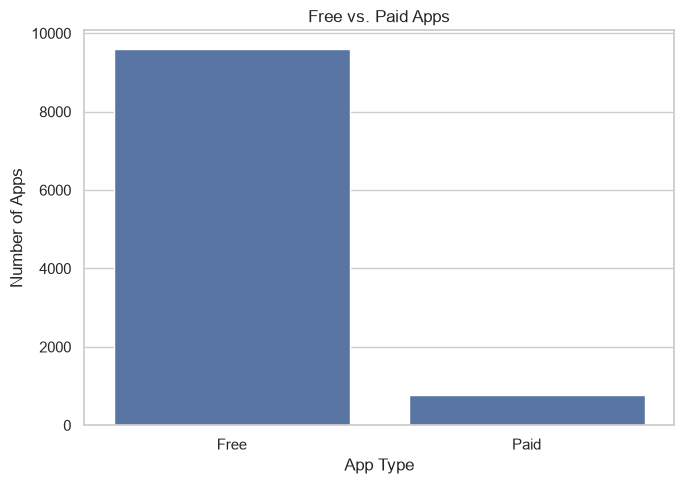

Free app percentage: 92.61 %
Paid app percentage: 7.39 %


In [16]:
# Create a free/paid label
apps_clean["App_Type"] = np.where(
    apps_clean["Price"] > 0,
    "Paid",
    "Free"
)

app_type_counts = apps_clean["App_Type"].value_counts()

display(app_type_counts.to_frame(name="Number_of_Apps"))

plt.figure(figsize=(7, 5))

sns.barplot(
    x=app_type_counts.index,
    y=app_type_counts.values
)

plt.title("Free vs. Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

print(
    "Free app percentage:",
    round((app_type_counts.get("Free", 0) / len(apps_clean)) * 100, 2),
    "%"
)

print(
    "Paid app percentage:",
    round((app_type_counts.get("Paid", 0) / len(apps_clean)) * 100, 2),
    "%"
)

Number of paid apps: 765

Paid app price statistics:


,Price
count,765.0
mean,13.955556
std,58.406966
min,0.99
25%,1.49
50%,2.99
75%,4.99
max,400.0


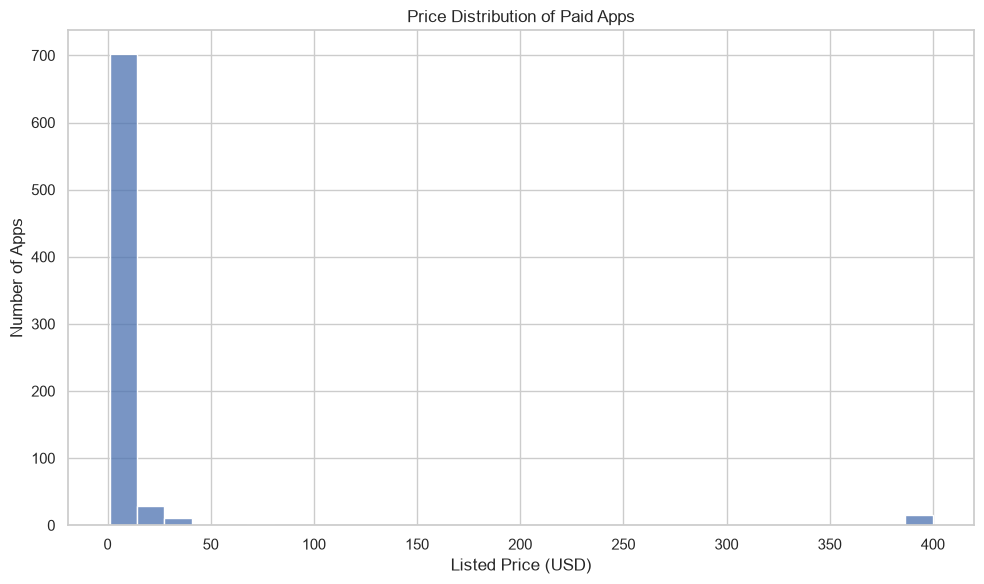

In [17]:
paid_apps = apps_clean[
    (apps_clean["Price"] > 0) &
    (apps_clean["Price"].notna())
].copy()

print("Number of paid apps:", len(paid_apps))
print("\nPaid app price statistics:")
display(paid_apps["Price"].describe().to_frame("Price"))

plt.figure(figsize=(10, 6))

sns.histplot(
    data=paid_apps,
    x="Price",
    bins=30
)

plt.title("Price Distribution of Paid Apps")
plt.xlabel("Listed Price (USD)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

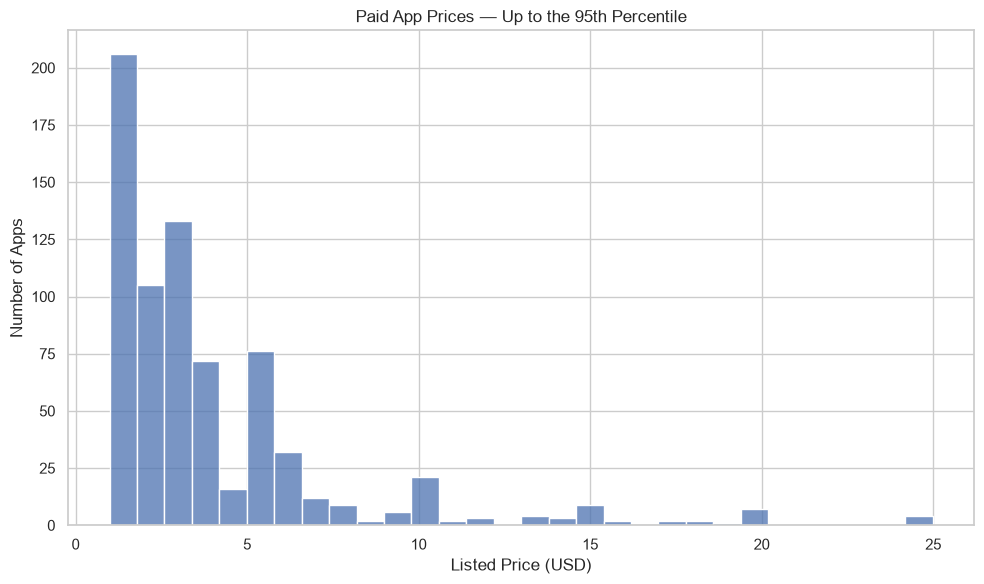

In [18]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=paid_apps[paid_apps["Price"] <= paid_apps["Price"].quantile(0.95)],
    x="Price",
    bins=30
)

plt.title("Paid App Prices — Up to the 95th Percentile")
plt.xlabel("Listed Price (USD)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

### Free vs. Paid Apps — Analysis

The charts compare free and paid apps and show how paid app prices are distributed. The second price chart limits the display to the 95th percentile to make the typical price range easier to inspect. This display limit does not remove those higher-priced apps from the dataset.

## 8. Estimated Revenue by Category

Estimate potential gross revenue for paid applications using listed price multiplied by reported installs. This is a simplified estimate rather than verified revenue because the dataset does not contain actual purchases, refunds, or net revenue.

Top 10 categories by estimated gross revenue:


,Estimated_Revenue_USD
Category,
FAMILY,185780335.36
LIFESTYLE,57583939.4
GAME,40987636.85
FINANCE,25726678.98
PHOTOGRAPHY,8942767.7
MEDICAL,8456535.67
PERSONALIZATION,7786947.56
TOOLS,5464820.59
SPORTS,4706211.95


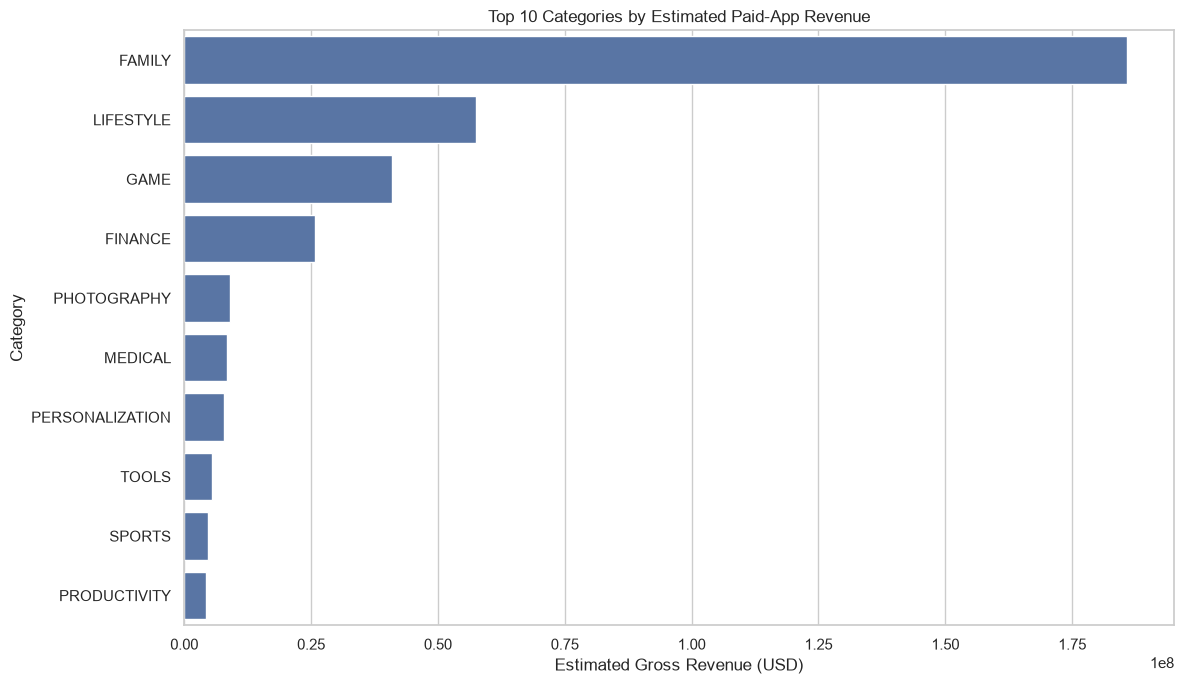

In [19]:
paid_apps = apps_clean[
    (apps_clean["Price"] > 0) &
    (apps_clean["Installs"] > 0)
].copy()

paid_apps["Estimated_Revenue_USD"] = (
    paid_apps["Price"] * paid_apps["Installs"]
)

revenue_by_category = (
    paid_apps.groupby("Category")["Estimated_Revenue_USD"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 categories by estimated gross revenue:")
display(
    revenue_by_category.head(10).to_frame(
        name="Estimated_Revenue_USD"
    ).round(2)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=revenue_by_category.head(10).values,
    y=revenue_by_category.head(10).index
)

plt.title("Top 10 Categories by Estimated Paid-App Revenue")
plt.xlabel("Estimated Gross Revenue (USD)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Estimated Revenue — Analysis

This chart ranks categories by the estimated gross value of paid-app installs. The estimate assumes each install corresponds to one purchase at the listed price. Actual revenue may differ substantially because of free trials, promotions, repeat installs, refunds, and platform fees. Therefore, this metric should be interpreted as an illustrative comparison, not actual earnings.

In [20]:
os.makedirs("output", exist_ok=True)

category_counts.rename("Number_of_Apps").to_csv(
    "output/category_distribution.csv"
)

category_ratings_filtered.to_csv(
    "output/category_ratings.csv"
)

app_type_counts.rename("Number_of_Apps").to_csv(
    "output/free_vs_paid.csv"
)

revenue_by_category.rename(
    "Estimated_Revenue_USD"
).to_csv("output/estimated_revenue_by_category.csv")

print("Category, rating, pricing, and revenue results saved in output/.")

Category, rating, pricing, and revenue results saved in output/.


## 9. Sentiment Analysis of User Reviews

Use TextBlob to analyze the polarity of user reviews. Polarity ranges from -1 to +1: negative values indicate negative sentiment, values near zero indicate neutral sentiment, and positive values indicate positive sentiment.

Sentiment analysis provides an approximate indication of user opinion and may not correctly interpret sarcasm, context, or every language pattern.

In [21]:
print("Review columns:", reviews_clean.columns.tolist())

required_columns = ["App", "Translated_Review"]

for col in required_columns:
    if col not in reviews_clean.columns:
        raise ValueError(f"Required column missing: {col}")

Review columns: ['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [22]:
# Create a separate copy for sentiment analysis
sentiment_df = reviews_clean.copy()

# Calculate TextBlob sentiment polarity
sentiment_df["Sentiment_Polarity"] = (
    sentiment_df["Translated_Review"]
    .apply(lambda text: TextBlob(str(text)).sentiment.polarity)
)

# Classify each review
def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

sentiment_df["Sentiment_Label"] = (
    sentiment_df["Sentiment_Polarity"].apply(classify_sentiment)
)

print("Sentiment analysis completed.")
display(
    sentiment_df[
        ["App", "Translated_Review",
         "Sentiment_Polarity", "Sentiment_Label"]
    ].head(10)
)

Sentiment analysis completed.


,App,Translated_Review,Sentiment_Polarity,Sentiment_Label
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,1.00,Positive
1,10 Best Foods for You,This help eating healthy exercise regular basis,0.25,Positive
3,10 Best Foods for You,Works great especially going grocery store,0.40,Positive
4,10 Best Foods for You,Best idea us,1.00,Positive
5,10 Best Foods for You,Best way,1.00,Positive
6,10 Best Foods for You,Amazing,0.60,Positive
8,10 Best Foods for You,"Looking forward app,",0.00,Neutral
9,10 Best Foods for You,It helpful site ! It help foods get !,0.00,Neutral
10,10 Best Foods for You,good you.,0.70,Positive
11,10 Best Foods for You,Useful information The amount spelling errors ...,0.20,Positive


### Overall Sentiment Analysis

The chart shows the distribution of positive, neutral, and negative reviews. A larger positive share may indicate favorable user experiences, while a larger negative share may highlight potential usability or quality concerns. These results reflect the available reviews and should not be treated as representative of every app user.

## 10. Sentiment Analysis by App Category

Merge the review sentiment results with app categories to compare user opinions across different categories. Because an app may have multiple reviews, app-level category information is attached to each matching review.

In [23]:
# Create a lookup table with one category per app name
app_categories = (
    apps_clean[["App", "Category"]]
    .dropna(subset=["App", "Category"])
    .drop_duplicates(subset=["App"])
)

sentiment_by_app = sentiment_df.merge(
    app_categories,
    on="App",
    how="inner"
)

print("Reviews before merge:", len(sentiment_df))
print("Reviews matched to app categories:", len(sentiment_by_app))

display(sentiment_by_app.head())

Reviews before merge: 29692
Reviews matched to app categories: 28250


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,Sentiment_Label,Category
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333,Positive,HEALTH_AND_FITNESS
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462,Positive,HEALTH_AND_FITNESS
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000,Positive,HEALTH_AND_FITNESS
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000,Positive,HEALTH_AND_FITNESS
4,10 Best Foods for You,Best way,Positive,1.00,0.300000,Positive,HEALTH_AND_FITNESS


In [24]:
category_sentiment = (
    sentiment_by_app.groupby("Category")
    .agg(
        Average_Polarity=("Sentiment_Polarity", "mean"),
        Total_Reviews=("Sentiment_Label", "size"),
        Positive_Reviews=(
            "Sentiment_Label",
            lambda x: (x == "Positive").sum()
        ),
        Negative_Reviews=(
            "Sentiment_Label",
            lambda x: (x == "Negative").sum()
        ),
        Neutral_Reviews=(
            "Sentiment_Label",
            lambda x: (x == "Neutral").sum()
        )
    )
)

category_sentiment["Positive_Percentage"] = (
    category_sentiment["Positive_Reviews"]
    / category_sentiment["Total_Reviews"] * 100
)

category_sentiment["Negative_Percentage"] = (
    category_sentiment["Negative_Reviews"]
    / category_sentiment["Total_Reviews"] * 100
)

# Filter out categories with very few reviews for more stable comparisons
category_sentiment_filtered = (
    category_sentiment[
        category_sentiment["Total_Reviews"] >= 20
    ]
    .sort_values("Average_Polarity", ascending=False)
)

print("Top 10 categories by average review polarity:")
display(category_sentiment_filtered.head(10).round(2))

print("\nBottom 10 categories by average review polarity:")
display(category_sentiment_filtered.tail(10).round(2))

Top 10 categories by average review polarity:


,Average_Polarity,Total_Reviews,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Percentage,Negative_Percentage
Category,,,,,,,
COMICS,0.45,45,39,1,5,86.67,2.22
EVENTS,0.38,156,123,16,17,78.85,10.26
AUTO_AND_VEHICLES,0.34,283,230,17,36,81.27,6.01
PARENTING,0.31,256,181,23,52,70.70,8.98
EDUCATION,0.30,644,488,75,81,75.78,11.65
HEALTH_AND_FITNESS,0.29,1621,1262,178,181,77.85,10.98
WEATHER,0.28,194,134,29,31,69.07,14.95
FOOD_AND_DRINK,0.28,583,432,78,73,74.10,13.38
PERSONALIZATION,0.27,961,668,140,153,69.51,14.57



Bottom 10 categories by average review polarity:


,Average_Polarity,Total_Reviews,Positive_Reviews,Negative_Reviews,Neutral_Reviews,Positive_Percentage,Negative_Percentage
Category,,,,,,,
PRODUCTIVITY,0.19,1135,758,208,169,66.78,18.33
DATING,0.18,1087,669,228,190,61.55,20.98
FINANCE,0.17,1336,841,300,195,62.95,22.46
COMMUNICATION,0.17,855,520,177,158,60.82,20.70
NEWS_AND_MAGAZINES,0.15,733,445,171,117,60.71,23.33
VIDEO_PLAYERS,0.14,326,185,83,58,56.75,25.46
ENTERTAINMENT,0.13,827,493,213,121,59.61,25.76
FAMILY,0.12,1802,1117,498,187,61.99,27.64
SOCIAL,0.11,661,367,190,104,55.52,28.74


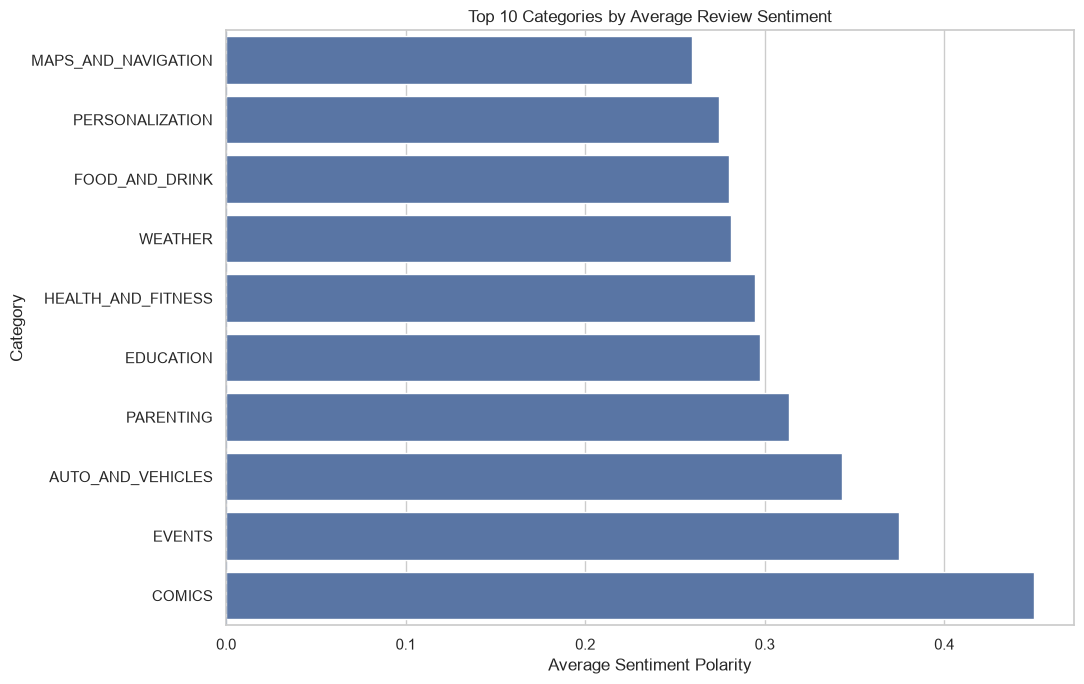

In [25]:
# Top categories by average polarity
top_sentiment_categories = (
    category_sentiment_filtered
    .sort_values("Average_Polarity", ascending=False)
    .head(10)
    .sort_values("Average_Polarity")
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_sentiment_categories.reset_index(),
    x="Average_Polarity",
    y="Category"
)

plt.axvline(0, linestyle="--")
plt.title("Top 10 Categories by Average Review Sentiment")
plt.xlabel("Average Sentiment Polarity")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

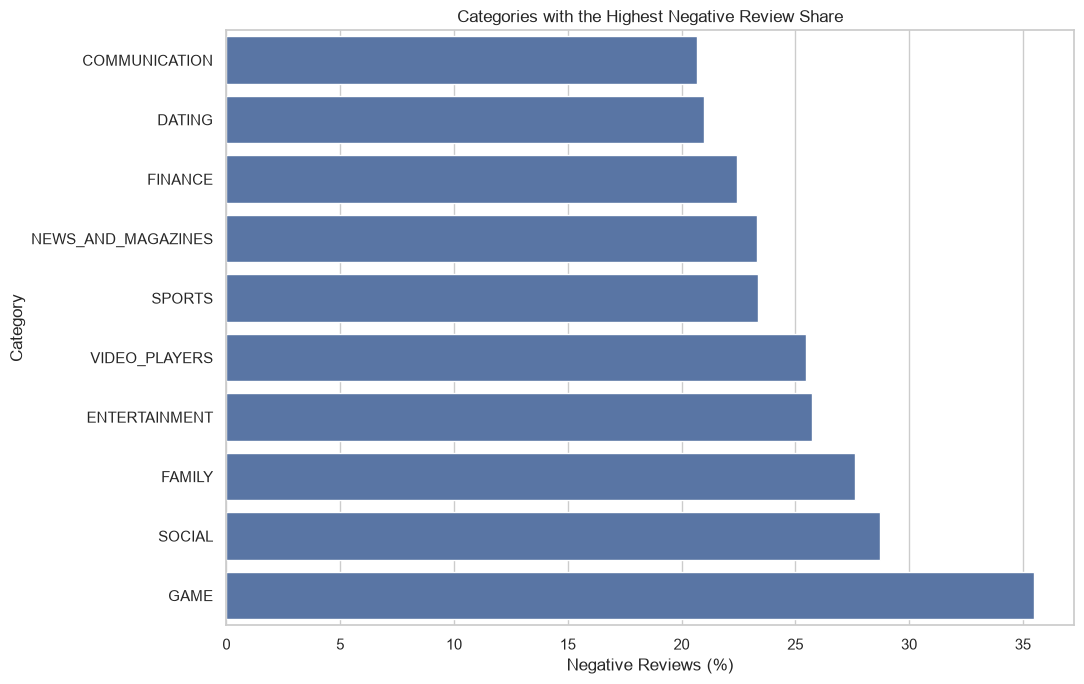

In [26]:
negative_categories = (
    category_sentiment_filtered
    .sort_values("Negative_Percentage", ascending=False)
    .head(10)
    .sort_values("Negative_Percentage")
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=negative_categories.reset_index(),
    x="Negative_Percentage",
    y="Category"
)

plt.title("Categories with the Highest Negative Review Share")
plt.xlabel("Negative Reviews (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### Sentiment by Category — Analysis

The category comparisons highlight differences in average review polarity and negative-review share. Categories with higher average polarity tend to have more favorable review language in this sample. Categories with a higher negative-review percentage may offer opportunities to improve reliability, usability, or customer support.

Only categories with at least 20 matched reviews are included in these comparisons. Review counts differ across categories, and TextBlob sentiment is an automated estimate rather than a manual assessment.

## 11. Interactive App Market Dashboard

Create an interactive Plotly visualization comparing app category size, average ratings, and review sentiment. Hover over the chart to inspect category-level information.

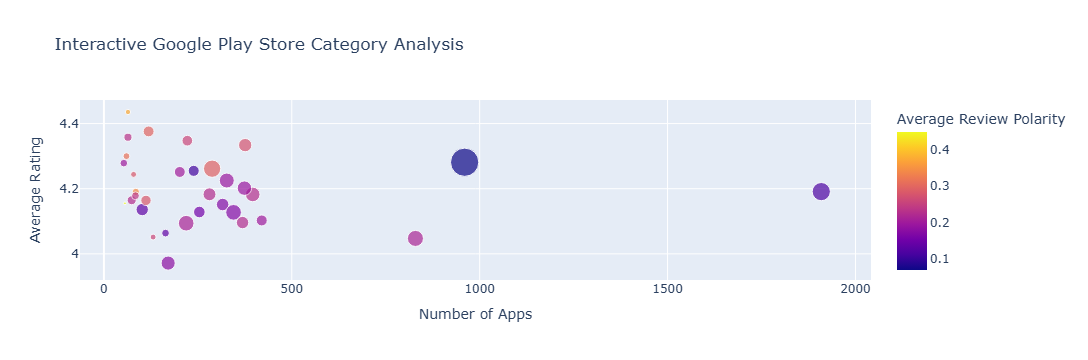

In [28]:
# Combine category-level app, rating, and sentiment data
category_dashboard = (
    apps_clean.groupby("Category")
    .agg(
        Number_of_Apps=("App", "nunique"),
        Average_Rating=("Rating", "mean")
    )
    .reset_index()
)

category_dashboard = category_dashboard.merge(
    category_sentiment[
        ["Average_Polarity", "Total_Reviews"]
    ].reset_index(),
    on="Category",
    how="left"
)

category_dashboard["Average_Polarity"] = (
    category_dashboard["Average_Polarity"].fillna(0)
)

category_dashboard["Total_Reviews"] = (
    category_dashboard["Total_Reviews"].fillna(0)
)

fig = px.scatter(
    category_dashboard,
    x="Number_of_Apps",
    y="Average_Rating",
    size="Total_Reviews",
    color="Average_Polarity",
    hover_name="Category",
    hover_data={
        "Number_of_Apps": True,
        "Average_Rating": ":.2f",
        "Average_Polarity": ":.3f",
        "Total_Reviews": True
    },
    title="Interactive Google Play Store Category Analysis",
    labels={
        "Number_of_Apps": "Number of Apps",
        "Average_Rating": "Average Rating",
        "Average_Polarity": "Average Review Polarity",
        "Total_Reviews": "Matched Reviews"
    }
)

fig.show()

In [29]:
os.makedirs("output", exist_ok=True)

fig.write_html(
    "output/interactive_category_dashboard.html"
)

print("Interactive Plotly dashboard saved successfully.")

Interactive Plotly dashboard saved successfully.


## 12. Key Insights for App Developers

Use the analysis results to identify three evidence-based insights for developers planning to launch a new application. Recommendations should be based on the observed category distribution, ratings, and review sentiment rather than assumptions.

In [30]:
print("=" * 65)
print("KEY INSIGHTS FOR APP DEVELOPERS")
print("=" * 65)

# Insight 1: Most crowded categories
if not category_counts.empty:
    print("\nINSIGHT 1: CATEGORY COMPETITION")

    print("Most crowded categories:")
    display(category_counts.head(3).to_frame("Number_of_Apps"))

    print(
        "Consider researching demand and competitor quality "
        "before entering these categories."
    )

# Insight 2: Highest-rated categories
if not category_ratings_filtered.empty:
    print("\nINSIGHT 2: APP RATINGS")

    display(
        category_ratings_filtered
        .sort_values("Average_Rating", ascending=False)
        .head(3)
        .round(2)
    )

    print(
        "Study the highly rated apps in these categories to "
        "understand features and user expectations."
    )

# Insight 3: Sentiment
if not category_sentiment_filtered.empty:
    print("\nINSIGHT 3: USER SENTIMENT")

    display(
        category_sentiment_filtered[
            [
                "Average_Polarity",
                "Negative_Percentage",
                "Total_Reviews"
            ]
        ]
        .sort_values("Negative_Percentage", ascending=False)
        .head(3)
        .round(2)
    )

    print(
        "Investigate categories with high negative-review shares "
        "to discover possible user pain points."
    )

KEY INSIGHTS FOR APP DEVELOPERS

INSIGHT 1: CATEGORY COMPETITION
Most crowded categories:


,Number_of_Apps
Category,
FAMILY,1943
GAME,1121
TOOLS,843


Consider researching demand and competitor quality before entering these categories.

INSIGHT 2: APP RATINGS


,Average_Rating,Rated_Apps
Category,,
EVENTS,4.44,45
EDUCATION,4.38,129
ART_AND_DESIGN,4.36,62


Study the highly rated apps in these categories to understand features and user expectations.

INSIGHT 3: USER SENTIMENT


,Average_Polarity,Negative_Percentage,Total_Reviews
Category,,,
GAME,0.07,35.47,4344
SOCIAL,0.11,28.74,661
FAMILY,0.12,27.64,1802


Investigate categories with high negative-review shares to discover possible user pain points.


### Interpretation of the Findings

1. **Competition:** A high app count indicates a crowded category, but developers should also investigate demand and download trends.
2. **Ratings:** Higher average ratings can reveal categories with favorable user feedback, although ratings alone do not guarantee commercial success.
3. **User sentiment:** Categories with more negative reviews may reveal unmet user needs. Review samples and individual comments should be examined before choosing a product opportunity.

The rankings above are generated from this dataset. They describe observed patterns and do not establish that a category will be profitable for a new app.

In [31]:
os.makedirs("output", exist_ok=True)

# 1. Cleaned apps dataset
apps_clean.to_csv(
    "output/cleaned_googleplaystore.csv",
    index=False
)

# 2. Cleaned review sentiment dataset
sentiment_df.to_csv(
    "output/reviews_with_sentiment.csv",
    index=False
)

# 3. Category distribution
category_counts.rename(
    "Number_of_Apps"
).to_csv(
    "output/category_distribution.csv"
)

# 4. Ratings by category
category_ratings.to_csv(
    "output/category_ratings.csv"
)

# 5. Free vs paid distribution
app_type_counts.rename(
    "Number_of_Apps"
).to_csv(
    "output/free_vs_paid.csv"
)

# 6. Estimated revenue
revenue_by_category.rename(
    "Estimated_Revenue_USD"
).to_csv(
    "output/estimated_revenue_by_category.csv"
)

# 7. Sentiment by category
category_sentiment.to_csv(
    "output/sentiment_by_category.csv"
)

# 8. Interactive dashboard source data
category_dashboard.to_csv(
    "output/category_dashboard_data.csv",
    index=False
)

print("All analysis results have been exported.")

All analysis results have been exported.


In [32]:
print("Files available in the output folder:")

for filename in sorted(os.listdir("output")):
    print("-", filename)

Files available in the output folder:
- category_dashboard_data.csv
- category_distribution.csv
- category_ratings.csv
- cleaned_googleplaystore.csv
- estimated_revenue_by_category.csv
- free_vs_paid.csv
- interactive_category_dashboard.html
- reviews_with_sentiment.csv
- sentiment_by_category.csv


## 13. Conclusion

This project analyzed the Google Play Store ecosystem using Python, pandas, NumPy, Matplotlib, Seaborn, TextBlob, and Plotly.

The analysis covered:

- Data cleaning, missing values, duplicates, and data type corrections.
- App category distribution and potential market competition.
- Rating distributions and average ratings by category.
- Relationships between app size and installs.
- Free and paid app pricing patterns.
- Illustrative paid-app revenue estimates by category.
- Positive, neutral, and negative user review sentiment.
- Sentiment comparisons across app categories.
- An interactive Plotly visualization.

### Key Takeaways

The category counts help identify crowded app markets. Rating and sentiment comparisons provide additional information about user experiences. Pricing and install data offer an exploratory view of app monetization.

These findings can help developers form hypotheses about market opportunities. However, actual launch decisions should also consider customer research, competition, development costs, and verified revenue data.

### Limitations

- The dataset represents a particular snapshot of the Google Play Store, not necessarily the current market.
- Missing ratings and sizes can affect comparisons.
- TextBlob sentiment is an approximate classification and may miss sarcasm or context.
- Estimated revenue is not actual revenue.
- Correlation between app size and installs does not imply causation.

Overall, this project demonstrates an end-to-end exploratory data analysis workflow with review sentiment analysis and interactive visualization.